In [1]:
# Make helpers.py importable, whatever folder Jupyter started the kernel in
import sys
from pathlib import Path

_candidates = [Path.cwd(), Path.cwd() / "code",
               *Path.cwd().glob("*/code"), *Path.cwd().glob("*/*/code")]
CODE = next(p for p in _candidates if (p / "helpers.py").is_file())
sys.path.insert(0, str(CODE))

In [2]:
# Generated with Claude (Anthropic): descriptive analysis of the analysis table
# (summary, funding rates, sectors, time, country characteristics).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from helpers import find_root

ROOT = find_root()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

df = pd.read_csv(PROCESSED / "analysis_table.csv")
reliefweb = pd.read_csv(RAW / "reliefweb_counts.csv")

# Same style for every figure of the paper
BLUE = "#2a78d6"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # fixed order for up to 4 series
INK, GREY = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "axes.axisbelow": True,
})

print(df.shape)

(7413, 18)


In [3]:
summary = pd.Series({
    "Rows (sector x appeal x year)": len(df),
    "Countries": df["countryCode"].nunique(),
    "Appeals": df["id"].nunique(),
    "Sectors": df["cluster"].nunique(),
    "Years": f'{df["year"].min()}-{df["year"].max()}',
    "Share underfunded (< 50% funded)": round(df["underfunded"].mean(), 3),
    "Share with no funding reported": round(df["no_funding_reported"].mean(), 3),
    "Share funded above 100%": round((df["funding_rate"] > 1).mean(), 3),
    "Median funding rate": round(df["funding_rate"].median(), 3),
}, name="value")
summary.to_csv(FIGURES / "table_summary.csv")
summary

Rows (sector x appeal x year)            7413
Countries                                  83
Appeals                                   740
Sectors                                    19
Years                               2000-2025
Share underfunded (< 50% funded)        0.636
Share with no funding reported          0.112
Share funded above 100%                 0.079
Median funding rate                     0.363
Name: value, dtype: object

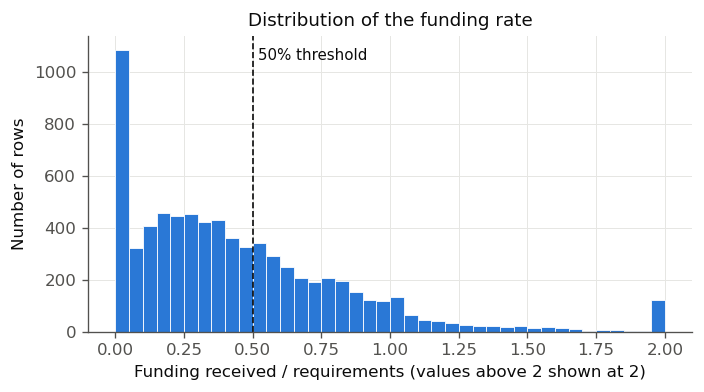

Share at exactly 0: 0.112
Share above 200%: 0.016


In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
rate = df["funding_rate"].clip(upper=2)          # rates above 200% shown in the last bar
ax.hist(rate, bins=np.arange(0, 2.05, 0.05), color=BLUE, edgecolor="white", linewidth=0.5)
ax.axvline(0.5, color=INK, linewidth=1, linestyle="--")
ax.text(0.52, ax.get_ylim()[1] * 0.92, "50% threshold", color=INK, fontsize=9)
ax.set_xlabel("Funding received / requirements (values above 2 shown at 2)")
ax.set_ylabel("Number of rows")
ax.set_title("Distribution of the funding rate")
fig.savefig(FIGURES / "fig_funding_rate.pdf")
plt.show()

print("Share at exactly 0:", round((df["funding_rate"] == 0).mean(), 3))
print("Share above 200%:", round((df["funding_rate"] > 2).mean(), 3))

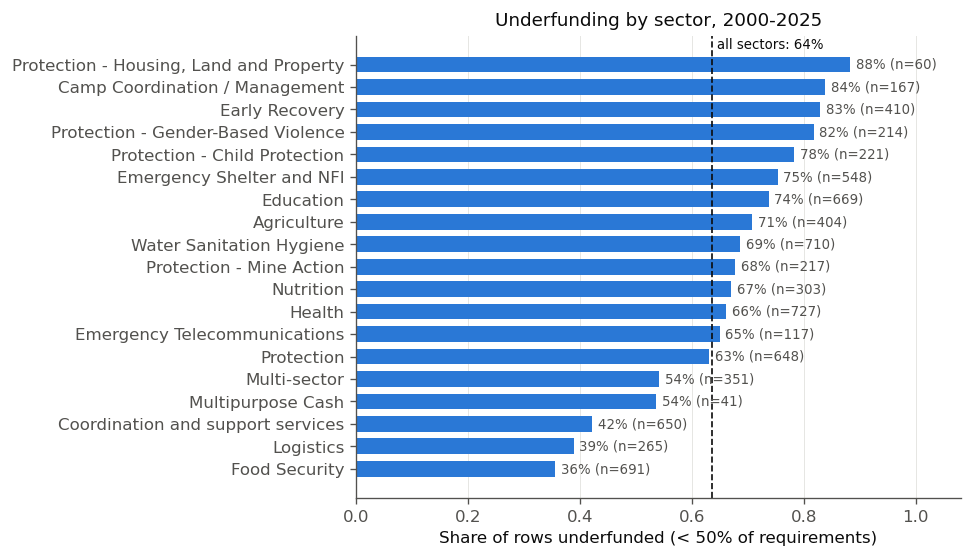

,share,rows
cluster,,
Food Security,0.36,691
Logistics,0.39,265
Coordination and support services,0.42,650
Multipurpose Cash,0.54,41
Multi-sector,0.54,351
Protection,0.63,648
Emergency Telecommunications,0.65,117
Health,0.66,727
Nutrition,0.67,303


In [5]:
by_sector = (df.groupby("cluster")["underfunded"]
               .agg(share="mean", rows="size")
               .sort_values("share"))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(by_sector.index, by_sector["share"], color=BLUE, height=0.7)
for i, (share, n) in enumerate(zip(by_sector["share"], by_sector["rows"])):
    ax.text(share + 0.01, i, f"{share:.0%} (n={n})", va="center", fontsize=8, color=GREY)
overall = df["underfunded"].mean()
ax.axvline(overall, color=INK, linewidth=1, linestyle="--")
ax.text(overall + 0.01, len(by_sector) - 0.3, f"all sectors: {overall:.0%}", fontsize=8, color=INK)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Share of rows underfunded (< 50% of requirements)")
ax.set_title("Underfunding by sector, 2000-2025")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "fig_underfunded_by_sector.pdf")
plt.show()

by_sector.round(2)

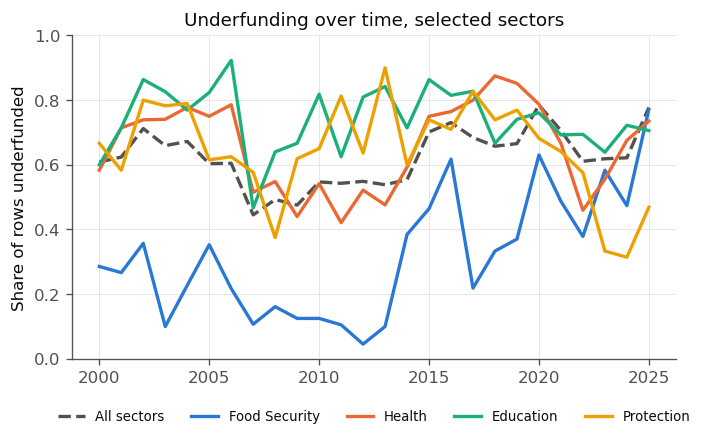

year
2000     92
2001    133
2002    198
2003    226
2004    235
2005    164
2006    248
2007    292
2008    274
2009    225
2010    223
2011    175
2012    235
2013    208
2014    267
2015    268
2016    323
2017    320
2018    292
2019    284
2020    446
2021    493
2022    442
2023    459
2024    460
2025    431


In [6]:
key_sectors = ["Food Security", "Health", "Education", "Protection"]
by_year = df.groupby("year")["underfunded"].mean()
by_year_sector = (df[df["cluster"].isin(key_sectors)]
                    .groupby(["year", "cluster"])["underfunded"].mean()
                    .unstack())

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(by_year.index, by_year, color=GREY, linewidth=2, linestyle="--", label="All sectors")
for color, sector in zip(SERIES, key_sectors):
    ax.plot(by_year_sector.index, by_year_sector[sector], color=color, linewidth=2, label=sector)
ax.set_ylim(0, 1)
ax.set_ylabel("Share of rows underfunded")
ax.set_title("Underfunding over time, selected sectors")
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.savefig(FIGURES / "fig_underfunded_over_time.pdf")
plt.show()

print(df.groupby("year").size().rename("rows per year").to_string())

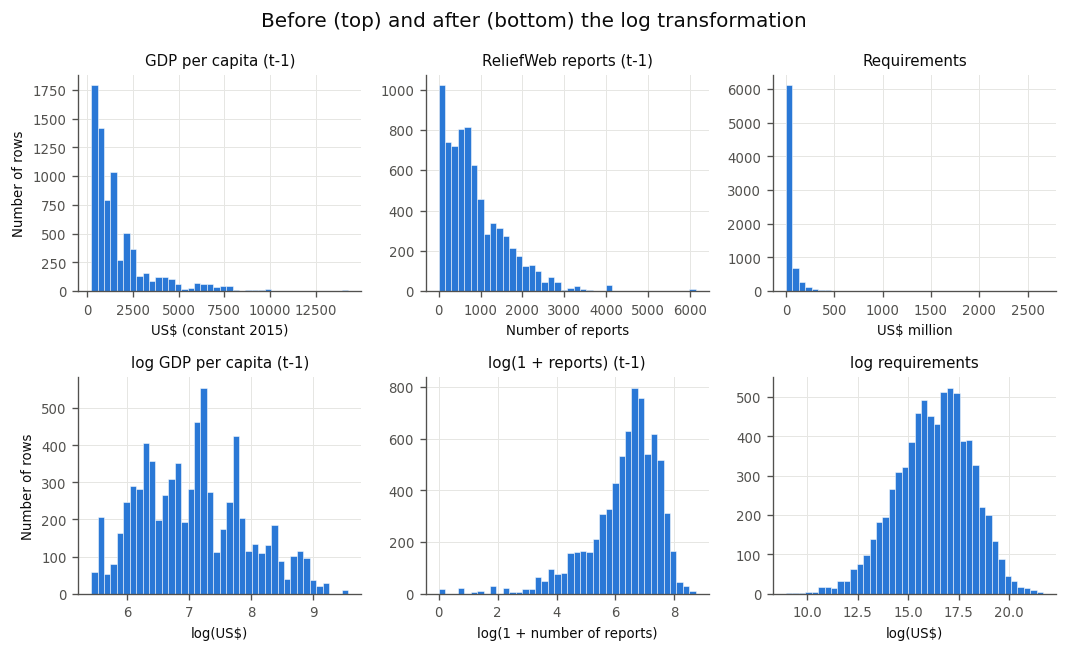

,count,mean,std,min,25%,50%,75%,max
gdp_pc_lag,7413.0,1729.12,1.756200e+03,226.44,588.22,1180.8,2206.66,1.427357e+04
gov_effectiveness_lag,7413.0,-1.05,5.800000e-01,-2.40,-1.53,-1.0,-0.63,7.100000e-01
control_corruption_lag,7413.0,-1.01,4.800000e-01,-1.81,-1.40,-1.1,-0.66,8.700000e-01
reports_lag,7413.0,881.56,7.539600e+02,0.00,328.00,706.0,1273.00,6.135000e+03
requirements,7413.0,48514252.72,1.253548e+08,7584.00,3500000.00,13100622.0,42427721.00,2.660000e+09


In [11]:
# Distributions before (top row) and after (bottom row) the log transformation
panels = [
    # (column, title, x-axis label, divide by)
    ("gdp_pc_lag", "GDP per capita (t-1)", "US$ (constant 2015)", 1),
    ("reports_lag", "ReliefWeb reports (t-1)", "Number of reports", 1),
    ("requirements", "Requirements", "US$ million", 1e6),
    ("log_gdp_pc_lag", "log GDP per capita (t-1)", "log(US$)", 1),
    ("log_reports_lag", "log(1 + reports) (t-1)", "log(1 + number of reports)", 1),
    ("log_requirements", "log requirements", "log(US$)", 1),
]

fig, axes = plt.subplots(2, 3, figsize=(9, 5.5))
for ax, (col, title, xlabel, scale) in zip(axes.flat, panels):
    ax.hist(df[col] / scale, bins=40, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(xlabel, fontsize=8)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:                      # left column only, to avoid repeating it
    ax.set_ylabel("Number of rows", fontsize=8)
fig.suptitle("Before (top) and after (bottom) the log transformation")
fig.tight_layout()
fig.savefig(FIGURES / "fig_distributions_log.pdf")
plt.show()

df[["gdp_pc_lag", "gov_effectiveness_lag", "control_corruption_lag",
    "reports_lag", "requirements"]].describe().round(2).T

In [8]:
model_vars = ["log_gdp_pc_lag", "gov_effectiveness_lag", "log_reports_lag",
              "log_requirements", "year"]
corr = df[model_vars].corr().round(2)
corr.to_csv(FIGURES / "table_correlations.csv")
corr

,log_gdp_pc_lag,gov_effectiveness_lag,log_reports_lag,log_requirements,year
log_gdp_pc_lag,1.00,0.48,-0.13,-0.12,0.15
gov_effectiveness_lag,0.48,1.00,-0.31,-0.28,0.13
log_reports_lag,-0.13,-0.31,1.00,0.49,0.28
log_requirements,-0.12,-0.28,0.49,1.00,0.25
year,0.15,0.13,0.28,0.25,1.00


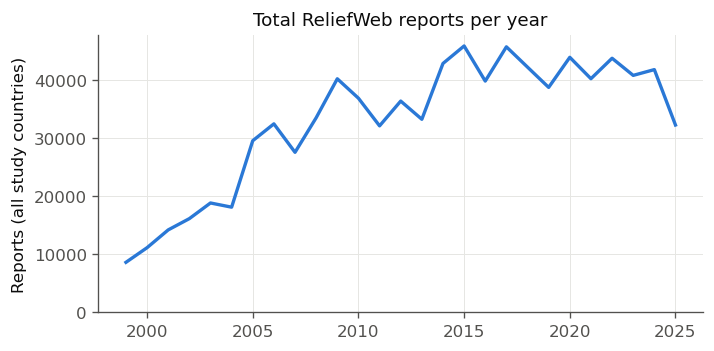

year
1999     8619
2000    11144
2001    14209
2002    16151
2003    18849
2004    18125
2005    29580
2006    32486
2007    27582
2008    33538
2009    40255
2010    36907
2011    32142
2012    36412
2013    33274
2014    42894
2015    45914
2016    39859
2017    45763
2018    42262
2019    38772
2020    43957
2021    40269
2022    43795
2023    40841
2024    41838
2025    32285


In [9]:
# Total ReliefWeb reports per year, summed over the countries of the study:
# does attention grow over time for everyone?
total = reliefweb.groupby("year")["reports"].sum()

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(total.index, total, color=BLUE, linewidth=2)
ax.set_ylim(0, None)
ax.set_ylabel("Reports (all study countries)")
ax.set_title("Total ReliefWeb reports per year")
fig.savefig(FIGURES / "fig_reliefweb_total.pdf")
plt.show()

print(total.to_string())

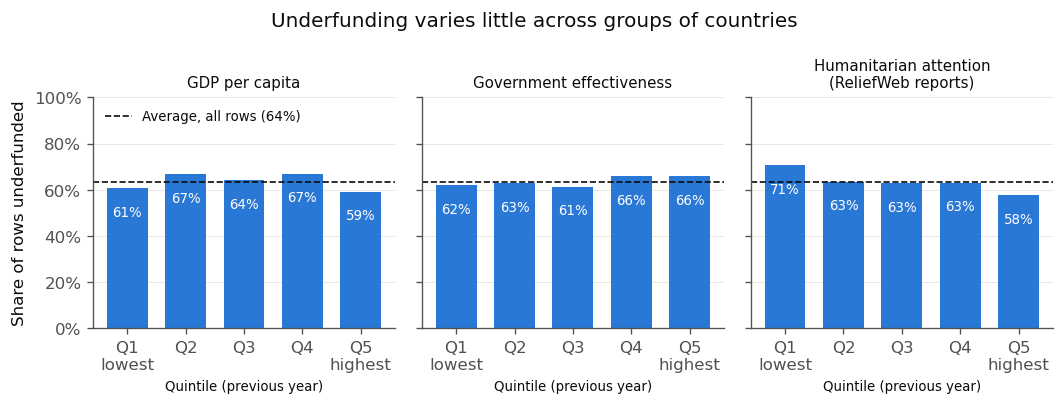

In [12]:
# Share underfunded by quintile of each country characteristic:
# rows are ranked from lowest to highest value and split into 5 equal groups
from matplotlib.ticker import PercentFormatter

characteristics = {"log_gdp_pc_lag": "GDP per capita",
                   "gov_effectiveness_lag": "Government effectiveness",
                   "log_reports_lag": "Humanitarian attention\n(ReliefWeb reports)"}
overall = df["underfunded"].mean()

fig, axes = plt.subplots(1, 3, figsize=(9, 3.4), sharey=True)
for ax, (col, label) in zip(axes, characteristics.items()):
    quintile = pd.qcut(df[col], 5, labels=["Q1\nlowest", "Q2", "Q3", "Q4", "Q5\nhighest"])
    share = df.groupby(quintile, observed=True)["underfunded"].mean()
    ax.bar(share.index.astype(str), share, color=BLUE, width=0.7)
    for i, v in enumerate(share):
        ax.text(i, v - 0.12, f"{v:.0%}", ha="center", fontsize=8, color="white")
    ax.axhline(overall, color=INK, linewidth=1, linestyle="--",
               label=f"Average, all rows ({overall:.0%})")
    ax.set_title(label, fontsize=9)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.set_xlabel("Quintile (previous year)", fontsize=8)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_ylabel("Share of rows underfunded")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Underfunding varies little across groups of countries")
fig.tight_layout()
fig.savefig(FIGURES / "fig_underfunded_by_quintile.pdf")
plt.show()